In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from IPython.display import display

In [6]:
matches = list(Path("/content").glob(
    "product-sales-data-mortgages-quarterly-2025.xlsx"
))

if matches:
    file_path = str(matches[0])
else:
    from google.colab import files
    uploaded = files.upload()
    file_path = next(iter(uploaded))

print("Excel file:", file_path)

Saving product-sales-data-mortgages-quarterly-2025 (1).xlsx to product-sales-data-mortgages-quarterly-2025 (1) (1).xlsx
Excel file: product-sales-data-mortgages-quarterly-2025 (1) (1).xlsx


In [7]:
df = pd.read_excel(
    file_path,
    sheet_name="PSD Mortgage Quarterly Data"
)


df.columns = df.columns.str.strip()


df["Number of sales"] = pd.to_numeric(
    df["Number of sales"],
    errors="coerce"
)


df["Year"] = df["Date"].str[:4].astype(int)
df["Quarter"] = df["Date"].str[-2:]

print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nSummary of data types and missing values:")
df.info()

Number of rows: 21677
Number of columns: 7

Column names:
['Mortgages Grouped By', 'Category', 'Postcode Region', 'Date', 'Number of sales', 'Year', 'Quarter']

First five rows:


,Mortgages Grouped By,Category,Postcode Region,Date,Number of sales,Year,Quarter
0,Lifetime mortgages sales,Lifetime Mortgage,East Midlands,2021 Q1,833.0,2021,Q1
1,Lifetime mortgages sales,Lifetime Mortgage,East Midlands,2021 Q2,798.0,2021,Q2
2,Lifetime mortgages sales,Lifetime Mortgage,East Midlands,2021 Q3,824.0,2021,Q3
3,Lifetime mortgages sales,Lifetime Mortgage,East Midlands,2021 Q4,903.0,2021,Q4
4,Lifetime mortgages sales,Lifetime Mortgage,East Midlands,2022 Q1,1003.0,2022,Q1



Summary of data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21677 entries, 0 to 21676
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Mortgages Grouped By  21677 non-null  object 
 1   Category              21677 non-null  object 
 2   Postcode Region       21677 non-null  object 
 3   Date                  21677 non-null  object 
 4   Number of sales       21677 non-null  float64
 5   Year                  21677 non-null  int64  
 6   Quarter               21677 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 1.2+ MB


In [8]:
print("Missing values per column:")
display(df.isnull().sum().to_frame("Missing values"))

print("Duplicate rows:", df.duplicated().sum())

print("Negative measurement values:",
      (df["Number of sales"] < 0).sum())

print("\nAvailable reporting periods:")
print(sorted(df["Date"].unique()))

print("\nAvailable analysis categories:")
display(
    df["Mortgages Grouped By"]
    .value_counts()
    .rename_axis("Analysis category")
    .to_frame("Number of rows")
)

Missing values per column:


,Missing values
Mortgages Grouped By,0
Category,0
Postcode Region,0
Date,0
Number of sales,0
Year,0
Quarter,0


Duplicate rows: 0
Negative measurement values: 0

Available reporting periods:
['2021 Q1', '2021 Q2', '2021 Q3', '2021 Q4', '2022 Q1', '2022 Q2', '2022 Q3', '2022 Q4', '2023 Q1', '2023 Q2', '2023 Q3', '2023 Q4', '2024 Q1', '2024 Q2', '2024 Q3', '2024 Q4', '2025 Q1', '2025 Q2', '2025 Q3', '2025 Q4']

Available analysis categories:


,Number of rows
Analysis category,
Number of sales by customer age bands,3098
Number of sales by mortgage term,2333
Number of first-time buyer sales by customer age bands,2064
Number of sales by loan-to-value (LTV) ratio,1952
Number of first-time-buyer sales by LTV ratio,1899
Number of sales by loan-to-value (LTV) ratio for new build properties,1808
Number of sales by loan amount bands,1300
Number of sales by type of borrower,1280
Number of sales by gross income bands,1039


In [9]:
age_group = "Number of sales by customer age bands"

age_data = df[
    df["Mortgages Grouped By"] == age_group
].copy()

# Total sales by quarter, across the listed regions
quarterly_sales = (
    age_data.groupby(["Year", "Quarter"])["Number of sales"]
    .sum()
    .reset_index()
)

quarterly_sales["Period"] = (
    quarterly_sales["Year"].astype(str)
    + " "
    + quarterly_sales["Quarter"]
)

print("Quarterly mortgage sales:")
display(quarterly_sales)

print("Total recorded sales across all quarters:",
      f"{quarterly_sales['Number of sales'].sum():,.0f}")

Quarterly mortgage sales:


,Year,Quarter,Number of sales,Period
0,2021,Q1,318821.0,2021 Q1
1,2021,Q2,333609.0,2021 Q2
2,2021,Q3,297941.0,2021 Q3
3,2021,Q4,274325.0,2021 Q4
4,2022,Q1,278549.0,2022 Q1
5,2022,Q2,279405.0,2022 Q2
6,2022,Q3,299753.0,2022 Q3
7,2022,Q4,293182.0,2022 Q4
8,2023,Q1,229130.0,2023 Q1
9,2023,Q2,207056.0,2023 Q2


Total recorded sales across all quarters: 5,286,015


In [10]:
# Percentage change compared with the previous quarter
quarterly_sales["Quarterly change (%)"] = (
    quarterly_sales["Number of sales"]
    .pct_change() * 100
)

# Percentage change compared with the same quarter one year earlier
quarterly_sales["Year-on-year change (%)"] = (
    quarterly_sales["Number of sales"]
    .pct_change(periods=4) * 100
)

display(
    quarterly_sales.round(2)
)

# Annual totals
annual_sales = (
    quarterly_sales.groupby("Year")["Number of sales"]
    .sum()
    .reset_index()
)

annual_sales["Annual change (%)"] = (
    annual_sales["Number of sales"].pct_change() * 100
)

print("Annual mortgage sales:")
display(annual_sales.round(2))

,Year,Quarter,Number of sales,Period,Quarterly change (%),Year-on-year change (%)
0,2021,Q1,318821.0,2021 Q1,NaN,NaN
1,2021,Q2,333609.0,2021 Q2,4.64,NaN
2,2021,Q3,297941.0,2021 Q3,-10.69,NaN
3,2021,Q4,274325.0,2021 Q4,-7.93,NaN
4,2022,Q1,278549.0,2022 Q1,1.54,-12.63
5,2022,Q2,279405.0,2022 Q2,0.31,-16.25
6,2022,Q3,299753.0,2022 Q3,7.28,0.61
7,2022,Q4,293182.0,2022 Q4,-2.19,6.87
8,2023,Q1,229130.0,2023 Q1,-21.85,-17.74
9,2023,Q2,207056.0,2023 Q2,-9.63,-25.89


Annual mortgage sales:


,Year,Number of sales,Annual change (%)
0,2021,1224696.0,NaN
1,2022,1150889.0,-6.03
2,2023,888342.0,-22.81
3,2024,941360.0,5.97
4,2025,1080728.0,14.80


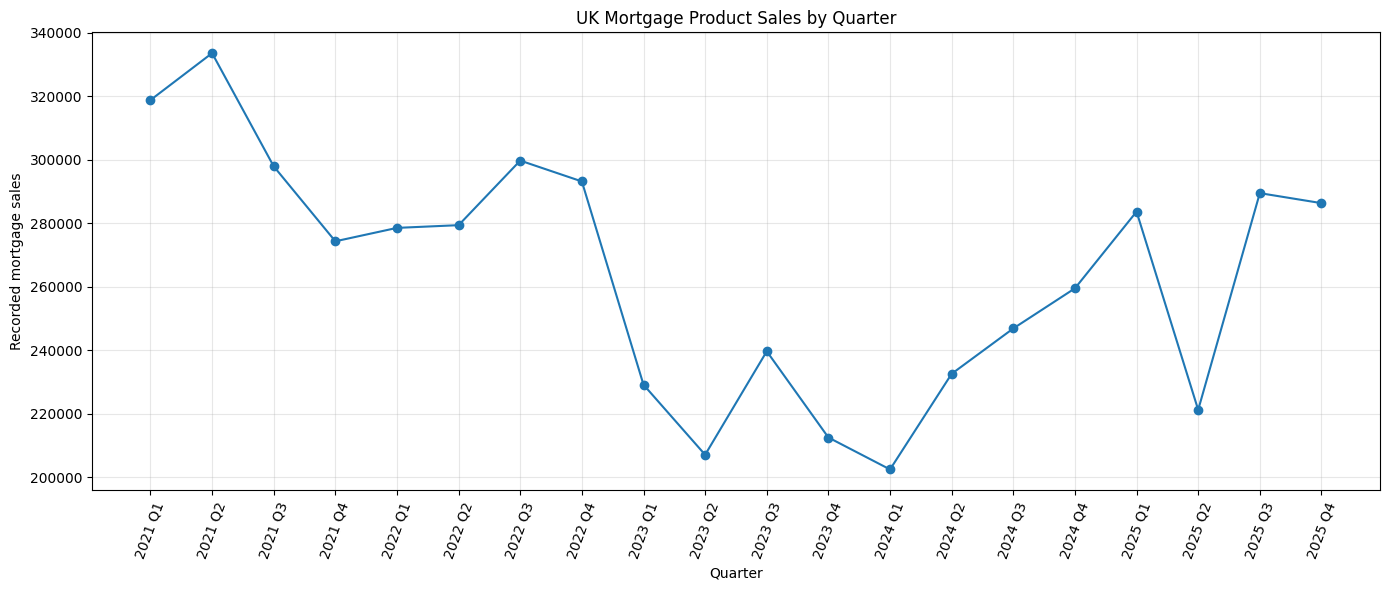

In [11]:
plt.figure(figsize=(14, 6))

plt.plot(
    quarterly_sales["Period"],
    quarterly_sales["Number of sales"],
    marker="o"
)

plt.title("UK Mortgage Product Sales by Quarter")
plt.xlabel("Quarter")
plt.ylabel("Recorded mortgage sales")
plt.xticks(rotation=70)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# Use the latest complete year in the dataset
analysis_year = 2025

age_2025 = age_data[
    age_data["Year"] == analysis_year
]

# Aggregate across all four quarters and listed regions
age_summary = (
    age_2025.groupby("Category")["Number of sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

age_summary.columns = ["Age band", "Recorded sales"]

# Calculate each age band's share of recorded sales
total_age_sales = age_summary["Recorded sales"].sum()

age_summary["Share of sales (%)"] = (
    age_summary["Recorded sales"]
    / total_age_sales * 100
)

print(f"Mortgage sales by customer age in {analysis_year}:")
display(age_summary.round(2))

Mortgage sales by customer age in 2025:


,Age band,Recorded sales,Share of sales (%)
0,31 - 35,207638.0,19.21
1,36 - 40,182512.0,16.89
2,26 - 30,179184.0,16.58
3,41 - 45,149079.0,13.79
4,46 - 50,106317.0,9.84
5,51 - 55,79421.0,7.35
6,18-25,75748.0,7.01
7,56 - 60,48134.0,4.45
8,61 - 65,24029.0,2.22
9,66 - 70,12612.0,1.17


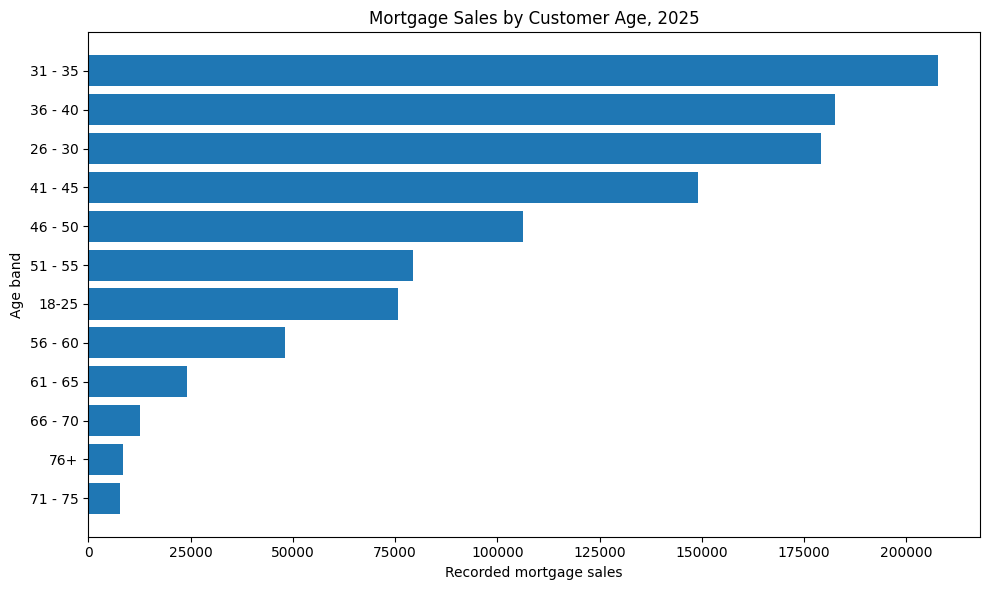

In [13]:
age_plot = age_summary.sort_values("Recorded sales")

plt.figure(figsize=(10, 6))

plt.barh(
    age_plot["Age band"],
    age_plot["Recorded sales"]
)

plt.title(f"Mortgage Sales by Customer Age, {analysis_year}")
plt.xlabel("Recorded mortgage sales")
plt.ylabel("Age band")
plt.tight_layout()
plt.show()

In [15]:
def analyse_sales_breakdown(group_name, year=2025):
    subset = df[
        (df["Mortgages Grouped By"] == group_name)
        & (df["Year"] == year)
    ].copy()

    if subset.empty:
        print("No data found for:", group_name)
        return None

    summary = (
        subset.groupby("Category")["Number of sales"]
        .sum()
        .sort_values(ascending=False)
        .reset_index()
    )

    summary.columns = ["Category", "Recorded sales"]

    total = summary["Recorded sales"].sum()

    summary["Share of breakdown (%)"] = (
        summary["Recorded sales"] / total * 100
    )

    print(f"\n{group_name} — {year}")
    print(f"Total recorded sales: {total:,.0f}")
    display(summary.round(2))

    plot_data = summary.sort_values("Recorded sales")

    plt.figure(figsize=(10, max(4, len(summary) * 0.45)))

    plt.barh(
        plot_data["Category"],
        plot_data["Recorded sales"]
    )

    plt.title(f"{group_name}, {year}")
    plt.xlabel("Recorded sales")
    plt.ylabel("Category")
    plt.tight_layout()
    plt.show()

    return summary


Number of sales by gross income bands — 2025
Total recorded sales: 1,080,728


,Category,Recorded sales,Share of breakdown (%)
0,"£50,001 - £100,000",506836.0,46.90
1,"£0 - £50,000",310769.0,28.76
2,"£100,001 +",217009.0,20.08
3,Unknown - Gross Income Band,46114.0,4.27


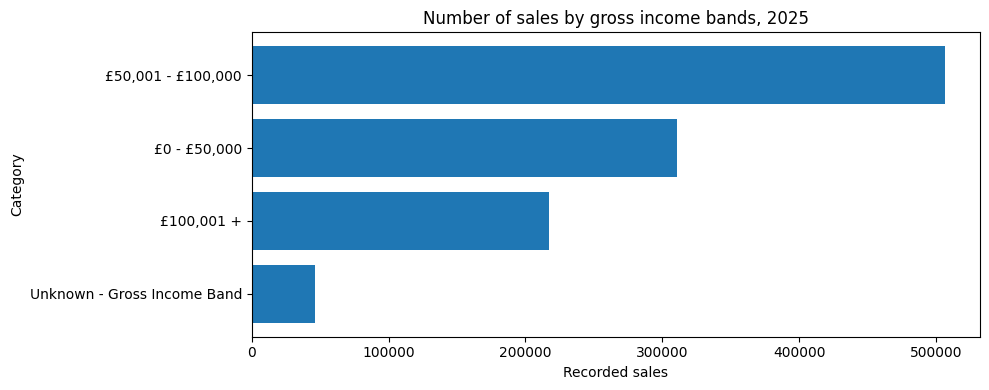

In [16]:
income_summary = analyse_sales_breakdown(
    "Number of sales by gross income bands"
)


Number of sales by credit history — 2025
Total recorded sales: 1,080,728


,Category,Recorded sales,Share of breakdown (%)
0,Mortgages advanced to people without an impair...,1070639.0,99.07
1,Mortgages advanced to people with an impaired ...,10089.0,0.93


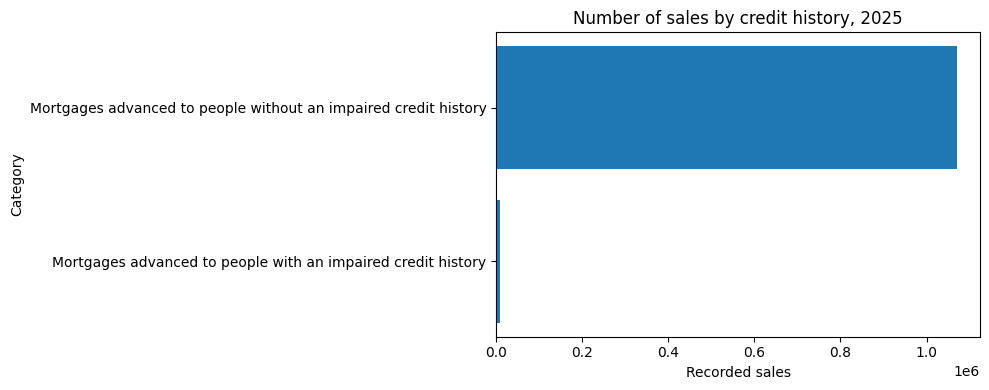

In [17]:
credit_summary = analyse_sales_breakdown(
    "Number of sales by credit history"
)


Number of sales by type of borrower — 2025
Total recorded sales: 1,080,728


,Category,Recorded sales,Share of breakdown (%)
0,First time buyer,380715.0,35.23
1,Home movers/second or subsequent buyers,328337.0,30.38
2,Remortgagors,324014.0,29.98
3,Other,36409.0,3.37
4,Council/registered social landlord tenant exer...,11253.0,1.04


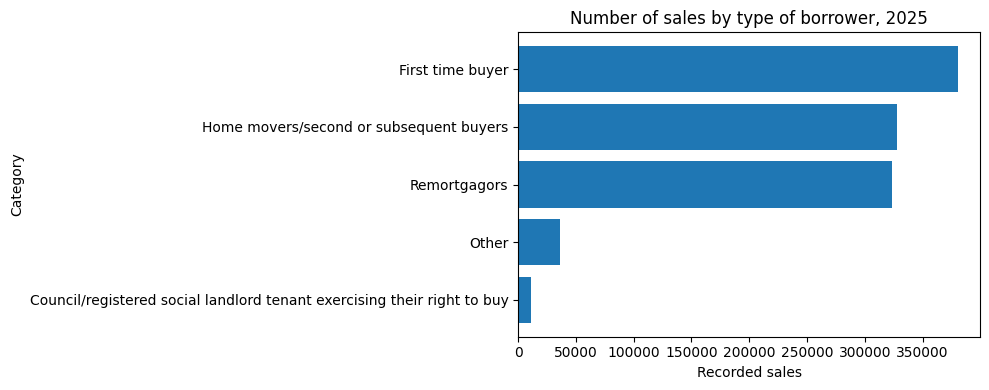

In [18]:
borrower_summary = analyse_sales_breakdown(
    "Number of sales by type of borrower"
)


Number of sales by advice given — 2025
Total recorded sales: 1,080,728


,Category,Recorded sales,Share of breakdown (%)
0,Advised sale,1044983.0,96.69
1,Non-advised sale,35745.0,3.31


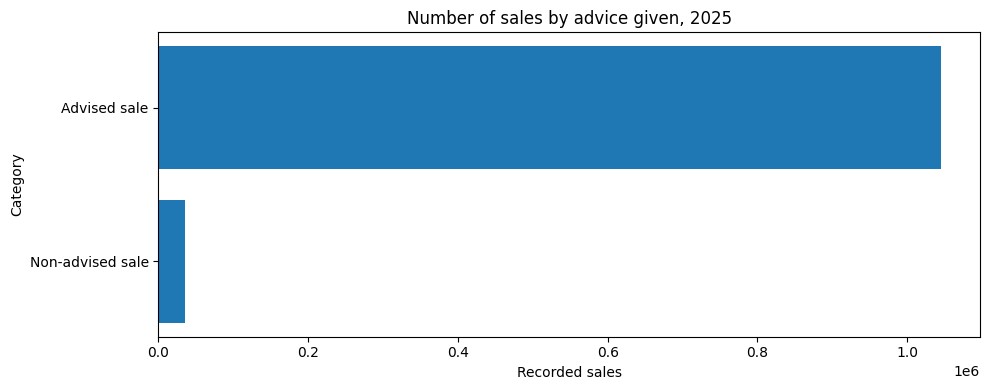


Number of sales by sales channel — 2025
Total recorded sales: 1,080,728


,Category,Recorded sales,Share of breakdown (%)
0,Intermediary,907393.0,83.96
1,Direct,173335.0,16.04


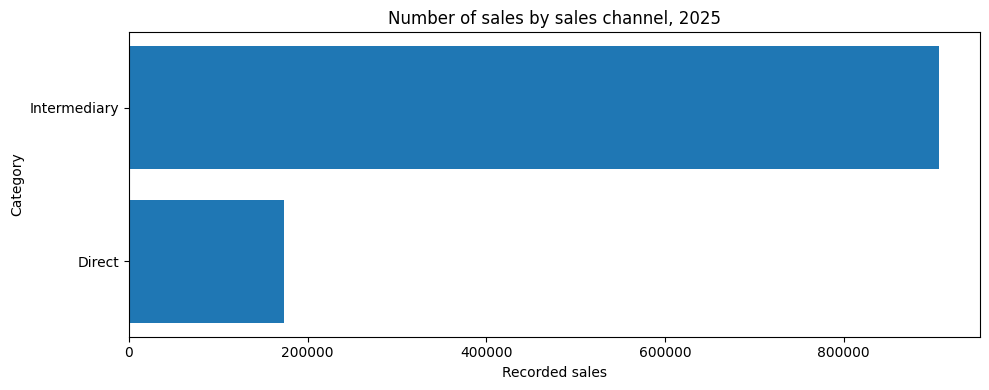

In [19]:
advice_summary = analyse_sales_breakdown(
    "Number of sales by advice given"
)

channel_summary = analyse_sales_breakdown(
    "Number of sales by sales channel"
)


Number of sales by interest rate type — 2025
Total recorded sales: 1,080,728


,Category,Recorded sales,Share of breakdown (%)
0,Fixed Rate,1041994.0,96.42
1,Variable Rate,37838.0,3.50
2,Other,896.0,0.08


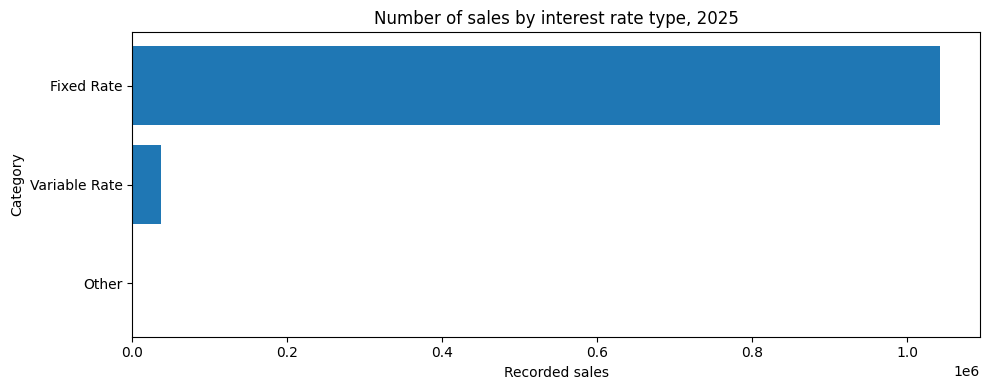


Number of sales by loan-to-value (LTV) ratio — 2025
Total recorded sales: 1,080,728


,Category,Recorded sales,Share of breakdown (%)
0,>50% - <=75%,313498.0,29.01
1,>75% - <=85%,190235.0,17.60
2,>85% - <=90%,158466.0,14.66
3,>30% - <=50%,155791.0,14.42
4,>90% - <=95%,127942.0,11.84
5,0% - <=30%,124381.0,11.51
6,>95%,10350.0,0.96
7,LTV Bands - Unspecified,65.0,0.01


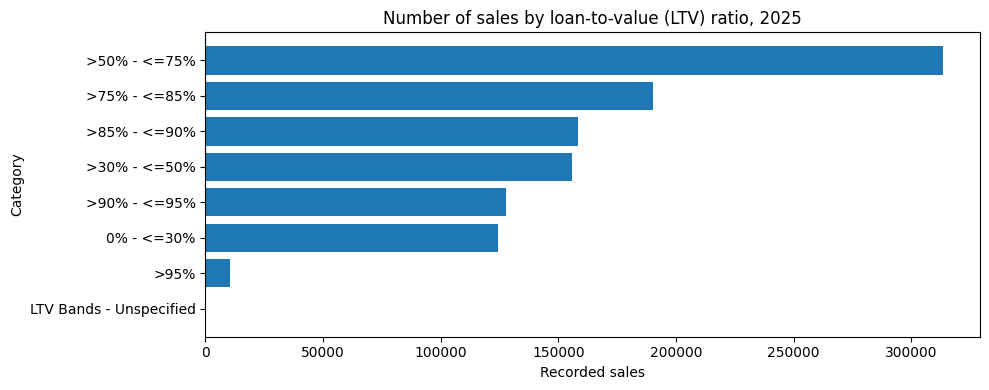


Number of sales by mortgage term — 2025
Total recorded sales: 1,080,728


,Category,Recorded sales,Share of breakdown (%)
0,>30 - 35 years,233663.0,21.62
1,>25 - 30 years,229994.0,21.28
2,>20 - 25 years,197381.0,18.26
3,>35 years,127132.0,11.76
4,>15 - 20 years,120046.0,11.11
5,>10 - 15 years,79239.0,7.33
6,>5 - 10 years,51871.0,4.80
7,Mortgage Term Bands - Unspecified,25341.0,2.34
8,0 - 5 years,16061.0,1.49


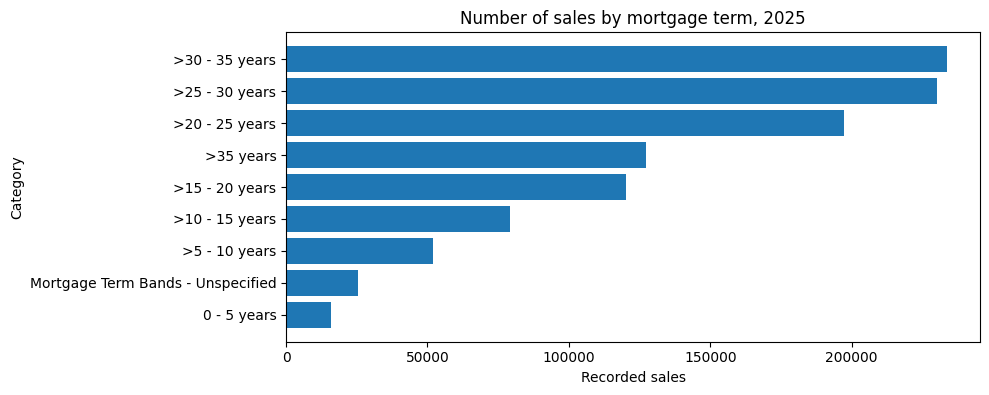


Number of sales by loan amount bands — 2025
Total recorded sales: 1,080,728


,Category,Recorded sales,Share of breakdown (%)
0,"£120,001 - £250,000",455327.0,42.13
1,"£250,001 - £500,000",312572.0,28.92
2,"£50,001 - £120,000",203400.0,18.82
3,"£500,001 +",62391.0,5.77
4,"£0 - £50,000",47038.0,4.35


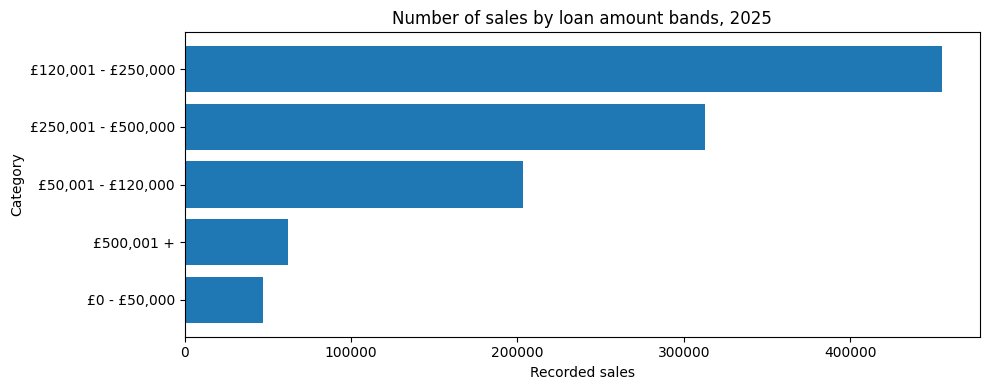


Number of sales by property value bands — 2025
Total recorded sales: 1,080,728


,Category,Recorded sales,Share of breakdown (%)
0,"£250,001 +",698270.0,64.61
1,"£120,001 - £250,000",340010.0,31.46
2,"£0 - £120,000",42448.0,3.93


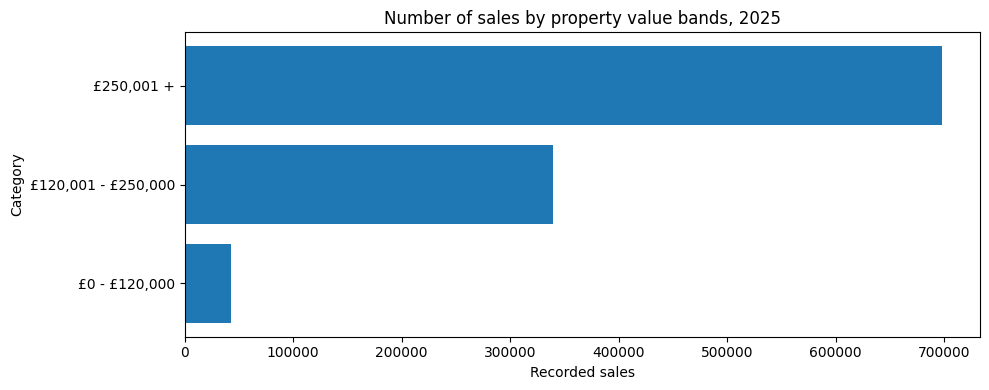

In [20]:
interest_summary = analyse_sales_breakdown(
    "Number of sales by interest rate type"
)

ltv_summary = analyse_sales_breakdown(
    "Number of sales by loan-to-value (LTV) ratio"
)

term_summary = analyse_sales_breakdown(
    "Number of sales by mortgage term"
)

loan_amount_summary = analyse_sales_breakdown(
    "Number of sales by loan amount bands"
)

property_value_summary = analyse_sales_breakdown(
    "Number of sales by property value bands"
)

In [21]:
regional_sales = (
    age_data[age_data["Year"] == 2025]
    .groupby("Postcode Region")["Number of sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

regional_sales.columns = [
    "Region",
    "Recorded sales"
]

regional_total = regional_sales["Recorded sales"].sum()

regional_sales["Share of sales (%)"] = (
    regional_sales["Recorded sales"]
    / regional_total * 100
)

print("Mortgage sales by region in 2025:")
display(regional_sales.round(2))

Mortgage sales by region in 2025:


,Region,Recorded sales,Share of sales (%)
0,South East,167314.0,15.48
1,North West,119913.0,11.10
2,London,116365.0,10.77
3,East of England,115149.0,10.65
4,South West,97977.0,9.07
5,West Midlands,88628.0,8.20
6,Scotland,88522.0,8.19
7,Yorkshire and The Humber,87368.0,8.08
8,East Midlands,87116.0,8.06
9,Wales,47144.0,4.36


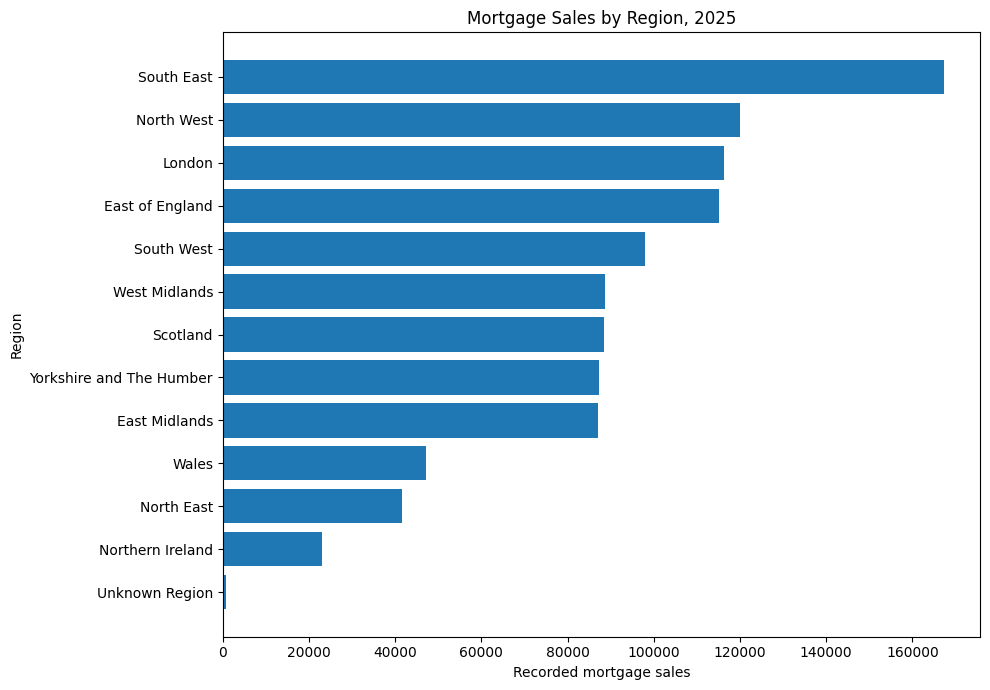

In [22]:
region_plot = regional_sales.sort_values("Recorded sales")

plt.figure(figsize=(10, 7))

plt.barh(
    region_plot["Region"],
    region_plot["Recorded sales"]
)

plt.title("Mortgage Sales by Region, 2025")
plt.xlabel("Recorded mortgage sales")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

In [23]:
highest = regional_sales.loc[
    regional_sales["Recorded sales"].idxmax()
]

lowest = regional_sales.loc[
    regional_sales["Recorded sales"].idxmin()
]

difference = (
    highest["Recorded sales"]
    - lowest["Recorded sales"]
)

print("Highest-sales region:", highest["Region"])
print("Highest recorded sales:", f"{highest['Recorded sales']:,.0f}")

print("\nLowest-sales region:", lowest["Region"])
print("Lowest recorded sales:", f"{lowest['Recorded sales']:,.0f}")

print("\nAbsolute difference:", f"{difference:,.0f}")

Highest-sales region: South East
Highest recorded sales: 167,314

Lowest-sales region: Unknown Region
Lowest recorded sales: 839

Absolute difference: 166,475


In [24]:
loan_medians = df[
    df["Mortgages Grouped By"] == "Median loan amounts (£)"
].copy()

# Average of the reported regional medians for each quarter.
# This is NOT the national median loan amount.
quarterly_median_averages = (
    loan_medians.groupby("Date")["Number of sales"]
    .mean()
    .reset_index(name="Unweighted mean of regional medians (£)")
)

display(quarterly_median_averages.round(2))

,Date,Unweighted mean of regional medians (£)
0,2021 Q1,168007.35
1,2021 Q2,170513.50
2,2021 Q3,163625.85
3,2021 Q4,165043.77
4,2022 Q1,170058.54
5,2022 Q2,177322.35
6,2022 Q3,184922.00
7,2022 Q4,184132.35
8,2023 Q1,173797.00
9,2023 Q2,175400.46


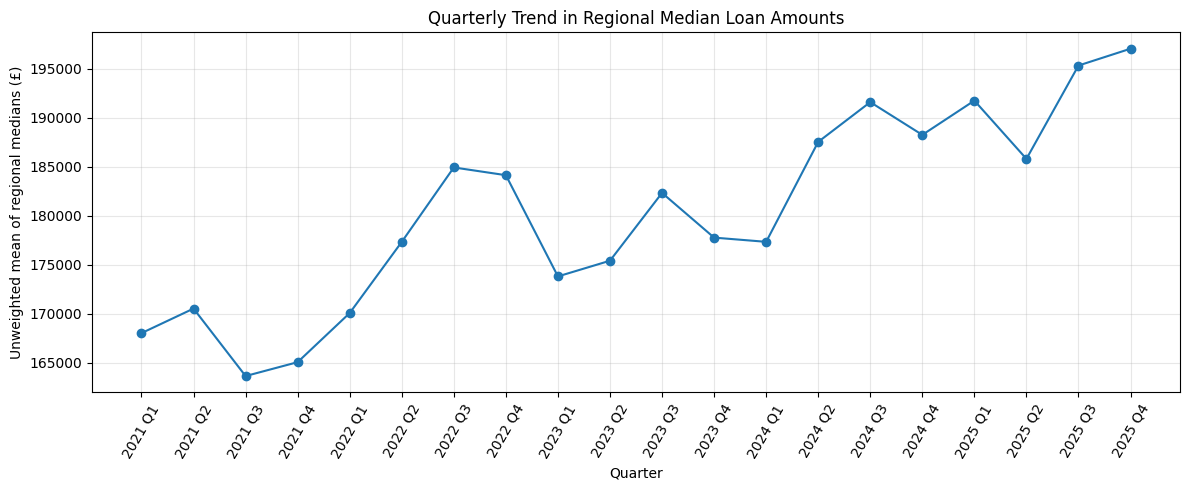

In [25]:
plt.figure(figsize=(12, 5))

plt.plot(
    quarterly_median_averages["Date"],
    quarterly_median_averages[
        "Unweighted mean of regional medians (£)"
    ],
    marker="o"
)

plt.title("Quarterly Trend in Regional Median Loan Amounts")
plt.xlabel("Quarter")
plt.ylabel("Unweighted mean of regional medians (£)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
ltv_medians = df[
    df["Mortgages Grouped By"]
    == "Median loan-to-value (LTV) ratios (%)"
].copy()

quarterly_ltv_averages = (
    ltv_medians.groupby("Date")["Number of sales"]
    .mean()
    .reset_index(name="Unweighted mean of regional median LTV (%)")
)

display(quarterly_ltv_averages.round(2))

,Date,Unweighted mean of regional median LTV (%)
0,2021 Q1,71.70
1,2021 Q2,72.79
2,2021 Q3,72.38
3,2021 Q4,70.83
4,2022 Q1,70.15
5,2022 Q2,71.41
6,2022 Q3,71.27
7,2022 Q4,69.97
8,2023 Q1,65.54
9,2023 Q2,68.59


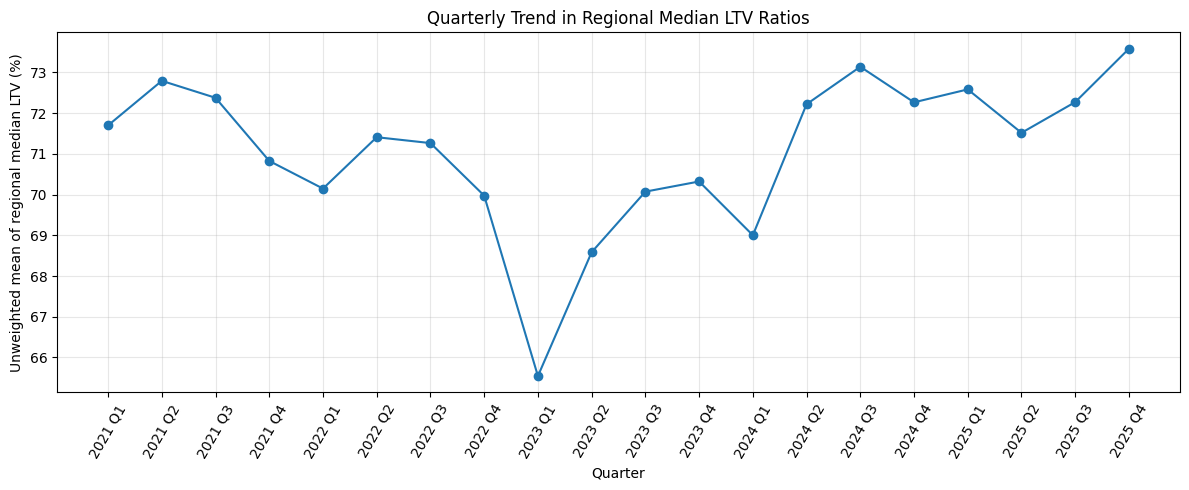

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(
    quarterly_ltv_averages["Date"],
    quarterly_ltv_averages[
        "Unweighted mean of regional median LTV (%)"
    ],
    marker="o"
)

plt.title("Quarterly Trend in Regional Median LTV Ratios")
plt.xlabel("Quarter")
plt.ylabel("Unweighted mean of regional median LTV (%)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
sales_groups = [
    "Number of sales by customer age bands",
    "Number of sales by gross income bands",
    "Number of sales by credit history",
    "Number of sales by type of borrower",
    "Number of sales by advice given",
    "Number of sales by interest rate type",
    "Number of sales by loan-to-value (LTV) ratio",
    "Number of sales by mortgage term",
    "Number of sales by sales channel",
    "Number of sales by property value bands",
    "Number of sales by loan amount bands"
]

validation_results = []

for group in sales_groups:
    subset = df[
        (df["Mortgages Grouped By"] == group)
        & (df["Year"] == 2025)
    ]

    validation_results.append({
        "Breakdown": group,
        "Number of rows": len(subset),
        "Total recorded sales": subset["Number of sales"].sum()
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df)

,Breakdown,Number of rows,Total recorded sales
0,Number of sales by customer age bands,618,1080728.0
1,Number of sales by gross income bands,208,1080728.0
2,Number of sales by credit history,103,1080728.0
3,Number of sales by type of borrower,253,1080728.0
4,Number of sales by advice given,104,1080728.0
5,Number of sales by interest rate type,151,1080728.0
6,Number of sales by loan-to-value (LTV) ratio,389,1080728.0
7,Number of sales by mortgage term,466,1080728.0
8,Number of sales by sales channel,104,1080728.0
9,Number of sales by property value bands,155,1080728.0


In [29]:
output_file = "/content/mortgage_analysis_results.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    quarterly_sales.to_excel(
        writer, sheet_name="Quarterly trends", index=False
    )
    annual_sales.to_excel(
        writer, sheet_name="Annual trends", index=False
    )
    age_summary.to_excel(
        writer, sheet_name="Age analysis", index=False
    )
    income_summary.to_excel(
        writer, sheet_name="Income analysis", index=False
    )
    credit_summary.to_excel(
        writer, sheet_name="Credit history", index=False
    )
    regional_sales.to_excel(
        writer, sheet_name="Regional analysis", index=False
    )
    quarterly_median_averages.to_excel(
        writer, sheet_name="Median loan amounts", index=False
    )
    quarterly_ltv_averages.to_excel(
        writer, sheet_name="Median LTV", index=False
    )
    validation_df.to_excel(
        writer, sheet_name="Data validation", index=False
    )

print("Analysis results saved to:", output_file)

Analysis results saved to: /content/mortgage_analysis_results.xlsx


In [30]:
from google.colab import files
files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
largest_age = age_summary.loc[
    age_summary["Recorded sales"].idxmax()
]

smallest_age = age_summary.loc[
    age_summary["Recorded sales"].idxmin()
]

print("Largest recorded sales share:")
print(largest_age["Age band"])
print(f"{largest_age['Share of sales (%)']:.2f}%")

print("\nSmallest recorded sales share:")
print(smallest_age["Age band"])
print(f"{smallest_age['Share of sales (%)']:.2f}%")

print("\nDifference in sales shares:")
print(
    f"{largest_age['Share of sales (%)'] - smallest_age['Share of sales (%)']:.2f}"
    " percentage points"
)

Largest recorded sales share:
31 - 35
19.21%

Smallest recorded sales share:
71 - 75
0.71%

Difference in sales shares:
18.50 percentage points
